#### K Means

In [1]:
import matplotlib.pyplot as plt
# Dataset
from sklearn.datasets import make_blobs
import numpy as np
import pandas as pd
%matplotlib inline

In [2]:
## Creating x and y axis, n_features = data points with 2 features, centers= columns(labels) , 
X,y= make_blobs(n_samples=1000,centers=3, n_features=2)

In [3]:
X

array([[ 7.6975988 , -6.10253536],
       [ 9.12273908, -1.84770637],
       [ 7.39470952, -2.43003248],
       ...,
       [-4.67065675, -6.74876809],
       [-2.92908817, -4.1900672 ],
       [ 7.43916716, -1.65356814]], shape=(1000, 2))

In [4]:
y # will not be used since it's unsupervised

array([0, 1, 1, 2, 1, 2, 0, 2, 1, 2, 0, 2, 1, 1, 0, 2, 1, 0, 1, 1, 1, 0,
       2, 2, 2, 0, 0, 0, 1, 2, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 2,
       2, 1, 1, 0, 2, 0, 1, 1, 1, 0, 1, 0, 1, 2, 0, 1, 0, 2, 2, 2, 2, 2,
       0, 0, 2, 0, 1, 2, 2, 0, 1, 1, 0, 0, 0, 2, 0, 1, 2, 1, 1, 1, 0, 2,
       1, 2, 1, 1, 1, 2, 1, 0, 2, 1, 1, 0, 2, 2, 1, 0, 0, 1, 0, 2, 2, 1,
       2, 2, 2, 1, 1, 2, 2, 0, 0, 0, 1, 0, 0, 1, 2, 2, 1, 1, 2, 0, 0, 0,
       2, 2, 2, 0, 2, 2, 2, 0, 1, 2, 2, 2, 0, 2, 2, 1, 0, 2, 1, 0, 1, 1,
       1, 0, 0, 0, 1, 0, 2, 0, 1, 0, 0, 1, 0, 1, 0, 2, 2, 2, 1, 1, 1, 1,
       0, 1, 2, 0, 0, 1, 1, 2, 1, 1, 2, 1, 0, 1, 2, 2, 2, 0, 2, 0, 1, 0,
       1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 2, 0, 1, 0, 2, 0, 2, 2, 0, 2, 0, 2,
       2, 2, 0, 2, 1, 2, 2, 2, 1, 0, 1, 0, 0, 0, 0, 2, 1, 2, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 2, 1, 2, 2, 1, 1, 0, 2, 1, 1, 2, 0, 2, 1, 1, 1, 0,
       2, 2, 1, 2, 0, 2, 0, 0, 1, 1, 1, 0, 0, 2, 2, 1, 1, 2, 2, 2, 1, 1,
       1, 1, 1, 2, 0, 0, 2, 1, 1, 2, 0, 2, 2, 2, 1,

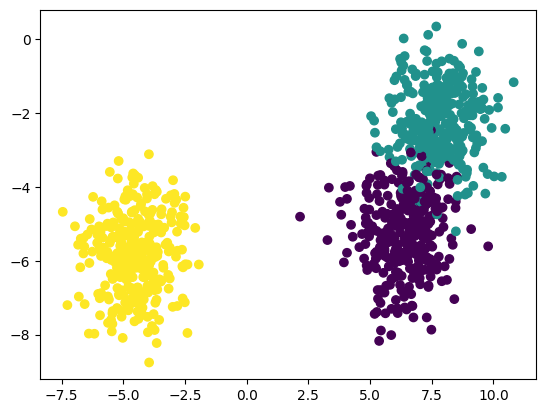

In [5]:
plt.scatter(X[:,0],X[:,1], c= y) # c= color value

#### Standardization  - Feature scaling technique

In [6]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

#### Train test split

In [7]:
from sklearn.model_selection import train_test_split

In [8]:
X_train, X_test, y_train , y_test = train_test_split(X,y, test_size=0.33, random_state=42)

In [9]:
## Feature scaling on X_train and test  data 
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [10]:
## importing k means
from sklearn.cluster import KMeans

In [11]:
## Elbow method to select k value
wcss =[]
for k in range(1,11):
    kmeans = KMeans(n_clusters=k, init="k-means++") ## init = initialization
    kmeans.fit(X_train_scaled)
    wcss.append(kmeans.inertia_)  ## different wcss wrt diff k values will be stored

C:\Users\Agam Katiyar\AppData\Roaming\Python\Python312\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Agam Katiyar\AppData\Roaming\Python\Python312\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\Agam Katiyar\Desktop\Data Science\Python\venv\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Agam Katiyar\Desktop\Data Science\Python\venv\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:

In [12]:
wcss

[1339.999999999999,
 499.25386712361114,
 200.86594553828635,
 148.42878121034792,
 126.91543980759448,
 78.05669288240618,
 69.35283705193022,
 62.825364894923545,
 48.45751841111139,
 45.22287400650235]

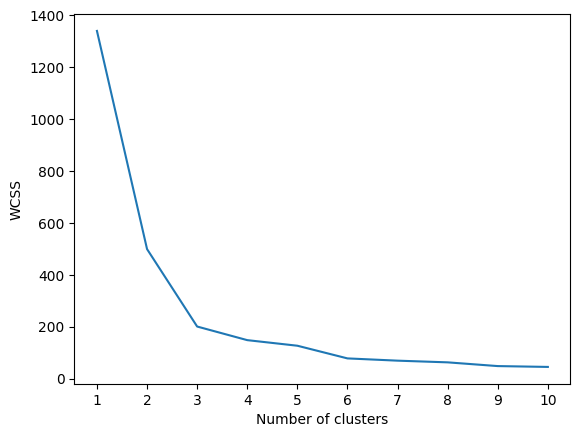

In [13]:
## Plotting elbow curve
plt.plot(range(1,11),wcss)
plt.xticks(range(1,11))
plt.xlabel("Number of clusters")
plt.ylabel("WCSS")
plt.show()

We can say by analysing the graph , that from k=3  , it is stabilizing , 3 is elbow point

we can use k = 3

In [20]:
kmeans = KMeans(n_clusters=3, init="k-means++")

In [21]:
kmeans.fit_predict(X_train_scaled)

array([2, 1, 1, 0, 0, 2, 0, 2, 1, 2, 1, 0, 2, 1, 1, 0, 1, 2, 2, 1, 2, 0,
       1, 0, 0, 0, 2, 1, 0, 0, 0, 0, 0, 2, 0, 2, 2, 0, 1, 2, 1, 1, 2, 2,
       0, 2, 1, 0, 0, 2, 0, 1, 2, 0, 1, 1, 1, 1, 1, 1, 2, 0, 2, 1, 2, 2,
       2, 0, 1, 1, 1, 2, 0, 1, 2, 0, 2, 0, 2, 2, 1, 0, 0, 1, 2, 2, 1, 1,
       2, 2, 2, 2, 0, 2, 2, 1, 2, 1, 1, 2, 2, 0, 2, 0, 1, 2, 2, 1, 0, 1,
       1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 2, 0, 1, 0, 2, 2, 2, 2, 2, 0, 2, 2,
       0, 2, 2, 0, 2, 1, 0, 1, 2, 2, 1, 1, 0, 2, 1, 1, 1, 1, 0, 0, 1, 2,
       0, 1, 2, 2, 2, 2, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 2, 2, 0, 2, 1, 1,
       0, 2, 0, 0, 1, 0, 0, 1, 0, 2, 0, 0, 2, 1, 2, 0, 1, 1, 2, 1, 0, 2,
       2, 1, 0, 1, 2, 2, 0, 2, 2, 2, 2, 1, 0, 0, 2, 1, 0, 0, 1, 2, 0, 2,
       1, 2, 1, 1, 2, 2, 2, 0, 2, 2, 0, 2, 0, 0, 0, 0, 0, 0, 0, 2, 1, 1,
       2, 2, 2, 1, 1, 2, 2, 0, 2, 0, 0, 0, 1, 0, 0, 1, 0, 2, 0, 0, 2, 1,
       1, 2, 2, 0, 0, 0, 0, 0, 1, 2, 0, 2, 1, 1, 1, 1, 0, 1, 2, 1, 0, 1,
       1, 1, 1, 2, 1, 0, 2, 1, 2, 1, 1, 0, 0, 0, 1,

In [22]:
y_pred = kmeans.predict(X_test_scaled)

In [23]:
y_pred

array([0, 1, 0, 1, 2, 0, 1, 0, 1, 1, 2, 0, 0, 1, 0, 1, 2, 1, 1, 2, 2, 2,
       2, 1, 2, 1, 1, 0, 0, 1, 1, 0, 1, 2, 1, 2, 0, 1, 1, 2, 1, 1, 0, 0,
       1, 1, 0, 1, 1, 1, 2, 1, 2, 0, 1, 0, 0, 0, 1, 2, 0, 2, 0, 0, 0, 1,
       1, 1, 2, 2, 1, 2, 2, 2, 1, 1, 1, 2, 0, 1, 0, 0, 0, 0, 2, 1, 1, 2,
       1, 0, 0, 1, 1, 0, 0, 1, 0, 2, 1, 0, 0, 0, 2, 2, 2, 1, 2, 0, 0, 1,
       1, 2, 0, 2, 0, 2, 2, 0, 1, 2, 0, 2, 0, 2, 1, 1, 0, 2, 0, 2, 0, 0,
       1, 1, 2, 0, 2, 1, 0, 1, 1, 1, 2, 1, 2, 2, 1, 0, 0, 0, 1, 2, 2, 1,
       2, 0, 0, 0, 0, 2, 0, 1, 2, 0, 1, 0, 1, 1, 2, 1, 1, 1, 1, 2, 2, 1,
       1, 1, 2, 0, 0, 1, 2, 0, 1, 1, 2, 2, 2, 0, 1, 2, 2, 0, 0, 1, 2, 1,
       1, 0, 1, 1, 2, 1, 0, 2, 2, 2, 1, 0, 1, 1, 2, 2, 0, 0, 2, 1, 0, 2,
       2, 1, 2, 0, 2, 2, 0, 0, 2, 0, 2, 2, 0, 0, 2, 2, 0, 0, 1, 0, 1, 2,
       0, 2, 2, 2, 0, 0, 2, 2, 1, 2, 1, 2, 1, 0, 0, 2, 2, 1, 0, 2, 2, 2,
       2, 0, 0, 1, 1, 2, 0, 0, 0, 1, 0, 1, 2, 1, 2, 1, 0, 2, 0, 0, 0, 0,
       2, 1, 1, 0, 2, 2, 1, 0, 0, 1, 2, 0, 1, 0, 0,

In [24]:
print("Unique predicted labels:", np.unique(y_pred))
print("Number of predicted clusters:", len(np.unique(y_pred)))

Unique predicted labels: [0 1 2]
Number of predicted clusters: 3


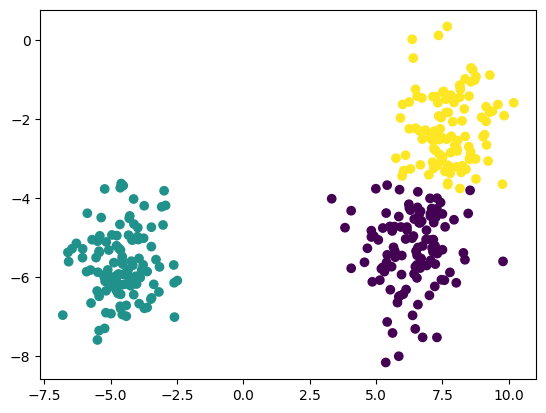

In [25]:
plt.scatter(X_test[:,0],X_test[:,1], c= y_pred)

#### Validating K values

Kneelocator

silhoutee scoring

In [26]:
## Knee locator
!pip install kneed

In [27]:
from kneed import KneeLocator

In [28]:
kl = KneeLocator(range(1,11), wcss, curve="convex", direction="decreasing")

In [29]:
kl.elbow

np.int64(3)

Validated

#### Silhoutee scoring

In [31]:
from sklearn.metrics import silhouette_score

In [32]:
silhoutee_coefficient =[]
for k in range(2,11):
    kmeans = KMeans(n_clusters= k, init="k-means++")
    kmeans.fit(X_train_scaled)
    score = silhouette_score(X_train_scaled, kmeans.labels_)
    silhoutee_coefficient.append(score)

In [33]:
silhoutee_coefficient

[0.5935267142278843,
 0.6057057116891783,
 0.5442452634983826,
 0.4967510169310339,
 0.4650888282309883,
 0.44242791904721057,
 0.4255155955879598,
 0.4071300600744382,
 0.39693110010531896]

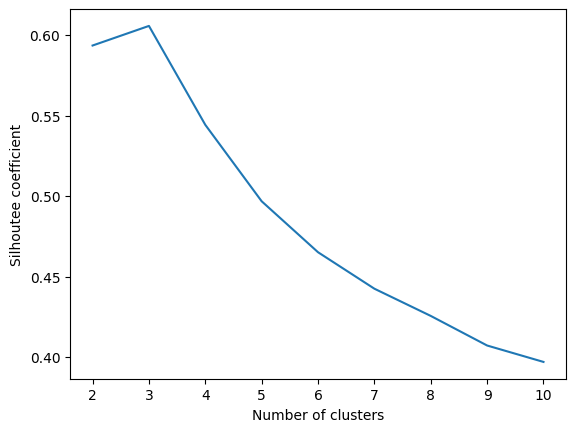

In [34]:
## Plotting silhoutee score
plt.plot(range(2,11), silhoutee_coefficient)
plt.xticks(range(2,11))
plt.xlabel("Number of clusters")
plt.ylabel("Silhoutee coefficient")
plt.show()

K values having highet silhoutee score is used 

so verified k =3 is good